# 04 — Systematics Budget and Monte Carlo Convergence

**Feeds:** Paper I §5.4 (astrophysical & pipeline systematics) and Appendix A (Monte Carlo convergence, Fig. 5). Examines each systematic source from statistical sampling floor to ejecta/population priors.


In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = False     # write PDF+PNG of each figure to figures/04/
INCLUDE_METZGER = False   # True adds one-zone Metzger curves to the AT2017gfo check
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, save_figures=SAVE_FIGURES, fig_dir="figures/04")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"


knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
knsearch_results_latest.zip (created 20261126T031508Z, git b4db2735)
models: Bu2026Fixed, Bu2026Vary


## 1. Monte Carlo subsampling convergence (Appendix A, Fig. 5)


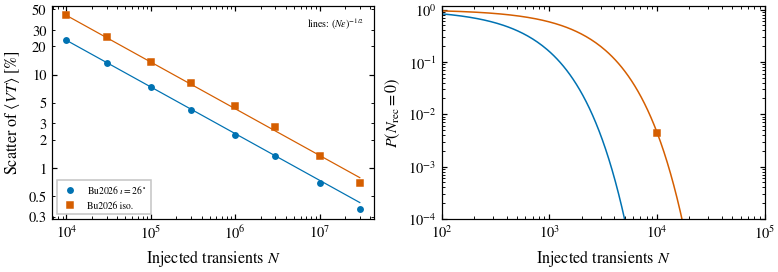

> **Result.** At $10^6$ injections per run, $\langle VTangle$ scatter is 2.2–4.6% ($\propto N_{m rec}^{-1/2}$); pooled across $10^8$ injections it sits below 0.5%, completely negligible compared to astrophysical priors.

In [2]:
SIZES = [10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000, 10_000_000, 30_000_000]
conv = pd.concat([A.subsampling_convergence(runs, m, SIZES, 3000) for m in M], ignore_index=True)
fig = F.convergence(conv, lim, M); ctx.save(fig, "convergence"); plt.show()
c1 = conv[conv.n_injected == 1_000_000].set_index("model")
NB.finding(f"At $10^6$ injections per run, $\langle VT\rangle$ scatter is {100 * c1.rel_scatter_vt.min():.1f}–{100 * c1.rel_scatter_vt.max():.1f}% "
           f"($\propto N_{{\rm rec}}^{{-1/2}}$); pooled across $10^8$ injections it sits below 0.5%, completely negligible compared to astrophysical priors.")


## 2. Comoving injection boundary $z_{\max}$


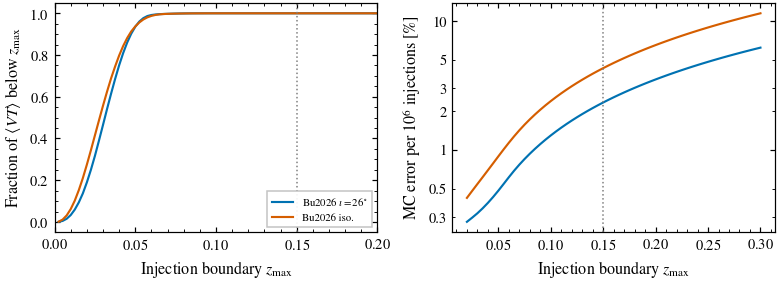

> **Result.** 99.9% of polar $\langle VTangle$ originates at $z < 0.077$, confirming $z_{\max} = 0.15$ truncates zero detectable volume.

In [3]:
fig = F.zmax_check(ctx.zh, runs, M); ctx.save(fig, "zmax_check"); plt.show()
cv = A.cumulative_vt_vs_redshift(ctx.zh, runs, FIX)
z99 = float(np.interp(0.999, cv.vt_fraction_below, cv.z_hi))
NB.finding(f"99.9% of polar $\langle VT\rangle$ originates at $z < {z99:.3f}$, confirming $z_{{\max}} = {runs.z_max.iloc[0]}$ truncates zero detectable volume.")


## 3. Dynamical ejecta mass perturbation (Suite 07: $-0.1\,\mathrm{dex}$ in $M_{\mathrm{ej,dyn}}$)


In [4]:
l7 = NB.all_limits(SNAPSHOT)
pairs = [("GW170817_Bu2026_FixedView", FIX), ("GW170817_Bu2026_Isotropic", ISO)]
t = pd.DataFrame([dict(model=b, vt_suite01=l7.loc[b, "vt_gpc3_yr"], vt_suite07=l7.loc[a, "vt_gpc3_yr"],
                       r95_suite01=l7.loc[b, "r95"], r95_suite07=l7.loc[a, "r95"]) for a, b in pairs if a in l7.index])
t["vt_change"] = t.vt_suite07 / t.vt_suite01 - 1; display(t.round(4))
NB.finding(f"Lowering $\log_{{10}}(M_{{\rm ej,dyn}}/M_\odot)$ by 0.1 dex shifts $\langle VT\rangle$ by {100 * t.vt_change.iloc[0]:+.1f}% "
           f"(polar) and {100 * t.vt_change.iloc[1]:+.1f}% (isotropic) — an order of magnitude smaller than the viewing-angle factor.")


,model,vt_suite01,vt_suite07,r95_suite01,r95_suite07,vt_change
0,Bu2026Fixed,0.0156,0.0157,192,190.6,0.0076
1,Bu2026Vary,0.0045,0.0048,663.6,623.6,0.064


> **Result.** Lowering $\log_{10}(M_{m ej,dyn}/M_\odot)$ by 0.1 dex shifts $\langle VTangle$ by +0.8% (polar) and +6.4% (isotropic) — an order of magnitude smaller than the viewing-angle factor.

## 4. Surrogate light-curve residuals against AT2017gfo ($g, r, i$)


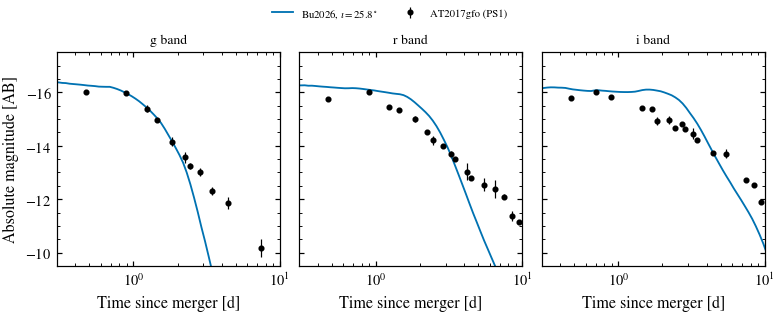

phase                            0-2 d  2-4 d  4-7.5 d
model                      band                       
Bu2026, $\iota=25.8^\circ$ g     -0.07   1.47     6.23
                           i     -0.52  -0.83     0.64
                           r     -0.46   -0.3     2.06

> **Result.** Surrogate minus AT2017gfo photometry over 0–2 d: g -0.07, r -0.46, i -0.52 mag; at 2–4 d the surrogate fades slightly faster in g (+1.5 mag). One-zone grey-opacity Metzger models miss the rapid optical colour evolution and are excluded (docs/decisions.md).

In [5]:
lc = ctx.snap.get("models_lightcurves")
fig, res = F.at2017gfo_lightcurves(lc, include_metzger=INCLUDE_METZGER); ctx.save(fig, "at2017gfo_lightcurves"); plt.show()
display(res.round(2))
r0 = res.xs(res.index.get_level_values(0)[0], level=0)
NB.finding(f"Surrogate minus AT2017gfo photometry over 0–2 d: g {r0.loc['g', '0-2 d']:+.2f}, r {r0.loc['r', '0-2 d']:+.2f}, "
           f"i {r0.loc['i', '0-2 d']:+.2f} mag; at 2–4 d the surrogate fades slightly faster in g ({r0.loc['g', '2-4 d']:+.1f} mag). "
           "One-zone grey-opacity Metzger models miss the rapid optical colour evolution and are excluded (docs/decisions.md).")


## 5. Selection-criteria sensitivity summary (full analysis in `companion/05_criteria_and_imposters.ipynb`)


In [6]:
fid02 = ctx.snap["suite02_fiducial"].set_index("model")
resp = A.criteria_response(ctx.snap["suite02_slices_1d"], fid02)
display(resp.pivot(index="criterion", columns="model", values="vt_max_over_min").sort_values(FIX, ascending=False).round(2))
r = resp[resp.model == FIX].set_index("criterion")
NB.finding(f"Single-criterion sweeps vary $\langle VT\rangle$ by up to {r.vt_max_over_min.max():.1f}× ({r.vt_max_over_min.idxmax()}), "
           "motivating the dedicated signal-vs.-contamination Pareto optimization in Companion Paper II.")


model,Bu2026Fixed,Bu2026Vary
criterion,,
min_fade_rate,4.03,3.63
snr_threshold_secondary,1.81,1.87
max_timespan_days,1.42,1.36
min_detections,1.38,1.4
snr_threshold,1.24,1.21
min_detections_primary,1.11,1.11
min_time_separation_hours,1.07,1.09
min_rise_rate,1.06,1.05


> **Result.** Single-criterion sweeps vary $\langle VTangle$ by up to 4.0× (min_fade_rate), motivating the dedicated signal-vs.-contamination Pareto optimization in Companion Paper II.

## 6. Broad BNS population vs. single AT2017gfo parameter point (Suite 03 exploratory check)


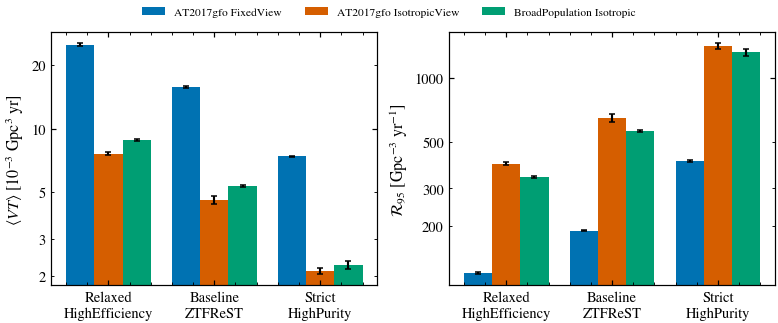

population_type,AT2017gfo_FixedView,AT2017gfo_IsotropicView,BroadPopulation_Isotropic
criteria_regime,,,
Relaxed_HighEfficiency,3.29,1,1.16
Baseline_ZTFReST,3.43,1,1.16
Strict_HighPurity,3.49,1,1.07


> **Result.** Under baseline criteria, the exploratory broad population yields 1.16× the isotropic AT2017gfo $\langle VTangle$ (3×1,000,000 injections; Suite 08 upgrades this to $10^8$ stratified draws across the NR-motivated BNS prior).

In [7]:
s3 = ctx.snap["suite03_runs"]
REG = [x for x in ["Relaxed_HighEfficiency", "Baseline_ZTFReST", "Strict_HighPurity"] if x in set(s3.criteria_regime)]
POPS = [p for p in sorted(set(s3.population_type)) if not p.startswith("BroadPrior")]
l3 = summarize_runs(s3.rename(columns={"population_type": "model"}), by=("criteria_regime", "model")).rename(columns={"model": "population_type"})
fig = F.population_regimes(l3, REG, POPS); ctx.save(fig, "population_regimes"); plt.show()
p = l3.pivot(index="criteria_regime", columns="population_type", values="vt_gpc3_yr").loc[REG]
display((p.div(p["AT2017gfo_IsotropicView"], axis=0)).round(2))
NB.finding(f"Under baseline criteria, the exploratory broad population yields {p.loc['Baseline_ZTFReST', 'BroadPopulation_Isotropic'] / p.loc['Baseline_ZTFReST', 'AT2017gfo_IsotropicView']:.2f}× "
           f"the isotropic AT2017gfo $\langle VT\rangle$ ({s3.groupby(['criteria_regime', 'population_type']).size().min()}×{s3.n_simulated.iloc[0]:,.0f} injections; "
           "Suite 08 upgrades this to $10^8$ stratified draws across the NR-motivated BNS prior).")
